# Experiment: Simulate Ca Imaging Video Visualizations

Objective:
- Reproduce the visual outputs implied by the original MATLAB repository with the Python port.
- Verify that the notebook can run without MATLAB by consuming saved comparison artifacts from `artifacts/runtime/stage2_visual_comparisons.npz`.
- Label each visualization with its source MATLAB file and function.

In [1]:
from __future__ import annotations

import json
import sys
import tempfile
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.io import loadmat

REPO_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents] if (candidate / "src").exists() and (candidate / "artifacts").exists()),
    None,
)
assert REPO_ROOT is not None, "Could not locate the repository root from the notebook working directory."
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from simulate_ca_imaging_video import BL_sim, Simulate_Ca_video, create_heart_mask, create_neuron_data, get_random_points
from simulate_ca_imaging_video._compat import crop_edges, get_data_path
from simulate_ca_imaging_video.add_nrmotion import Add_NRmotion
from simulate_ca_imaging_video.cali_ali_mirror.vesselness2d import vesselness2d
from simulate_ca_imaging_video.simulate_ca_video import create_baseline, int_var

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.titlesize"] = 10

metrics = json.loads((REPO_ROOT / "artifacts" / "reports" / "stage2_metrics.json").read_text())
comparisons = np.load(REPO_ROOT / "artifacts" / "runtime" / "stage2_visual_comparisons.npz")
SEED = 1
len(metrics), sorted(comparisons.files)

(20,
 ['baseline_matlab',
  'baseline_python',
  'spatial_matlab',
  'spatial_python',
  'vesselness_matlab',
  'vesselness_python'])

## Source MATLAB: `Simulate_Ca_video.m / create_baseline`

The MATLAB pipeline synthesizes session baselines from the bundled `BL.mat` bank. The first row below shows the Python baseline, the stored MATLAB reference used for parity testing, and the absolute difference heatmap.

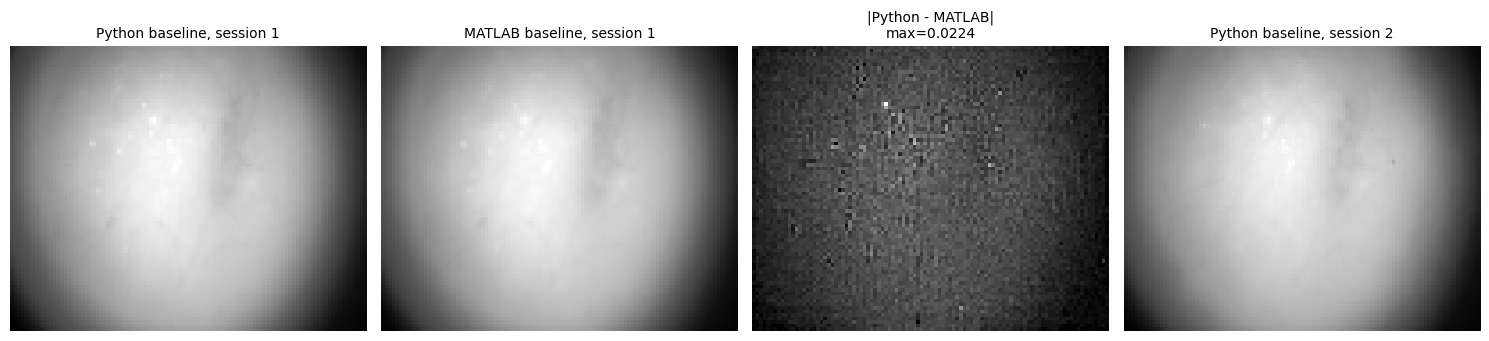

In [2]:
baseline_opt = int_var(d=[80, 100], ses=2, B=1, seed=SEED, save_videos=False, save_mat=False, save_GT=False)
baseline = create_baseline(baseline_opt)
baseline_py = comparisons["baseline_python"]
baseline_mat = comparisons["baseline_matlab"]
baseline_diff = np.abs(baseline_py - baseline_mat)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
axes[0].imshow(baseline[:, :, 0])
axes[0].set_title("Python baseline, session 1")
axes[1].imshow(baseline_mat)
axes[1].set_title("MATLAB baseline, session 1")
axes[2].imshow(baseline_diff)
axes[2].set_title(f"|Python - MATLAB|\nmax={baseline_diff.max():.4f}")
axes[3].imshow(baseline[:, :, 1])
axes[3].set_title("Python baseline, session 2")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Source MATLAB: `create_neuron_data.m / create_spatial`

`create_neuron_data.m` visualizes maximum projections of the neuron footprints and background components. The Python recreation shows those live outputs and the stored MATLAB comparison used in the parity suite.

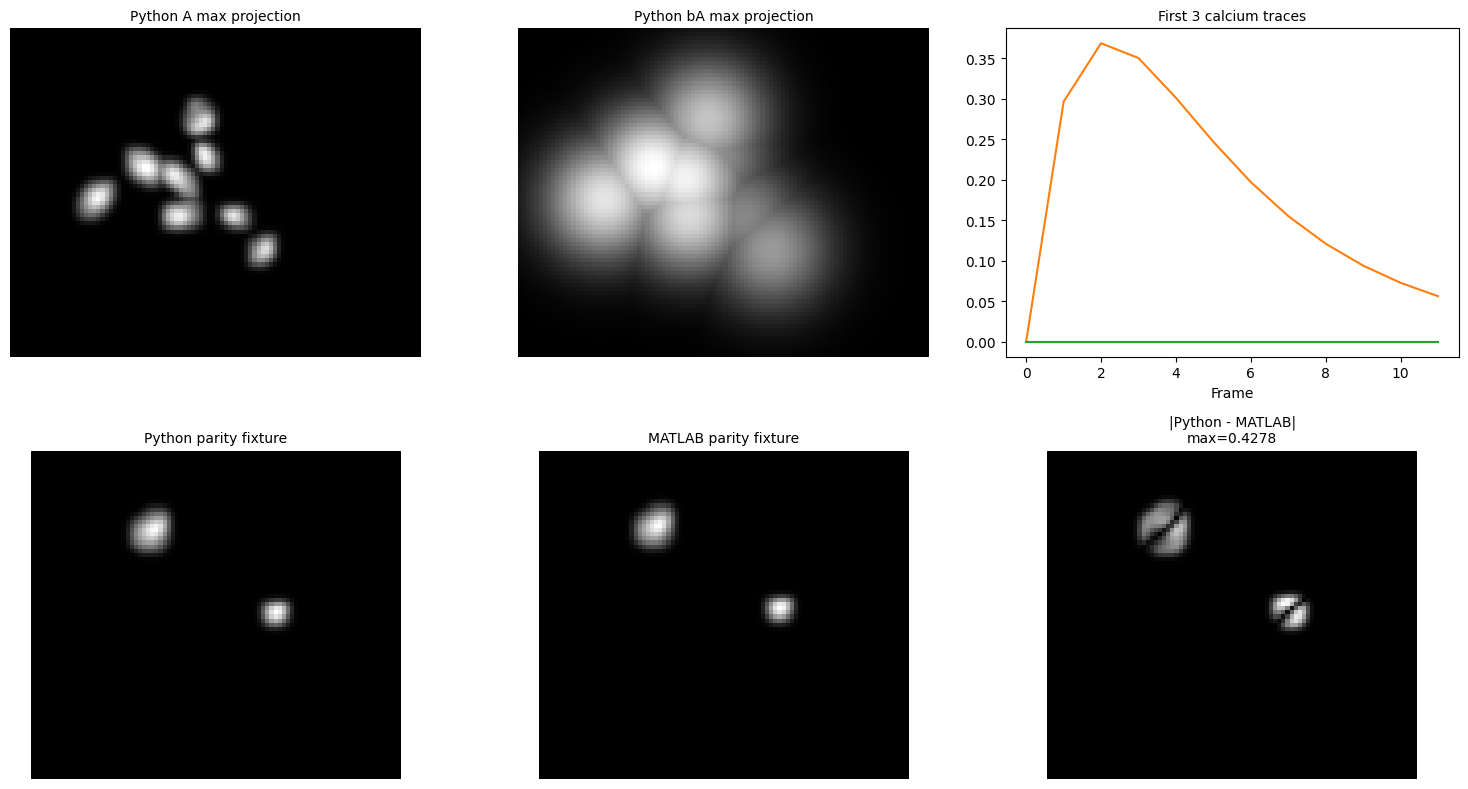

In [3]:
neuron_opt = int_var(
    Nneu=8,
    ses=2,
    F=24,
    d=[80, 100],
    save_videos=False,
    save_mat=False,
    save_GT=False,
    session_motion_std=0,
    seed=SEED,
)
a, ba, c, s, lfp = create_neuron_data(neuron_opt)
spatial_py = comparisons["spatial_python"]
spatial_mat = comparisons["spatial_matlab"]
spatial_diff = np.abs(spatial_py - spatial_mat)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(np.max(a[0], axis=2))
axes[0, 0].set_title("Python A max projection")
axes[0, 1].imshow(np.max(ba[0], axis=2))
axes[0, 1].set_title("Python bA max projection")
axes[0, 2].plot(c[:3, :12].T)
axes[0, 2].set_title("First 3 calcium traces")
axes[0, 2].set_xlabel("Frame")
axes[1, 0].imshow(spatial_py)
axes[1, 0].set_title("Python parity fixture")
axes[1, 1].imshow(spatial_mat)
axes[1, 1].set_title("MATLAB parity fixture")
axes[1, 2].imshow(spatial_diff)
axes[1, 2].set_title(f"|Python - MATLAB|\nmax={spatial_diff.max():.4f}")
for ax in axes[:, :2].ravel():
    ax.axis("off")
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

## Source MATLAB: `Add_NRmotion.m`

The original MATLAB helper optionally plots the original image, the displacement field, the warped image, and an overlay. This cell recreates the same diagnostic view from the Python port.

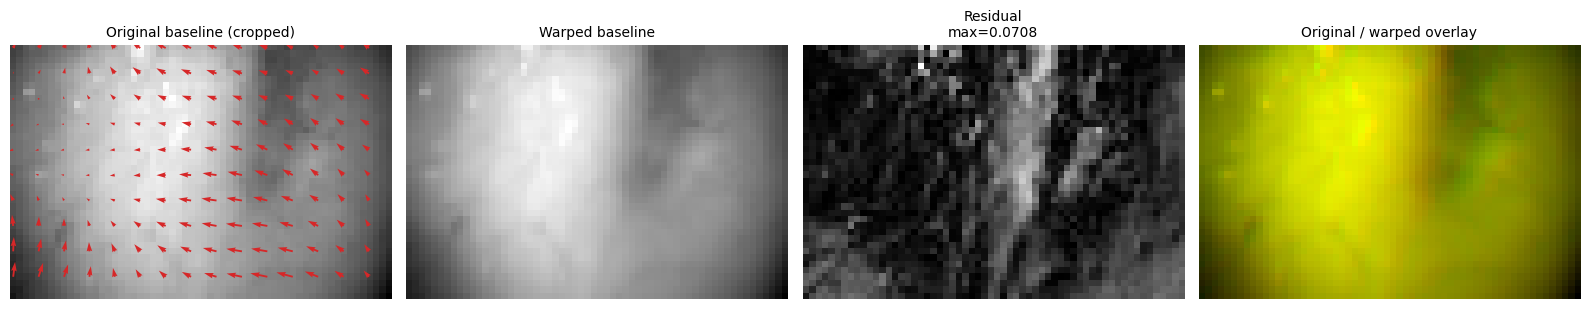

In [4]:
motion_input = baseline[:, :, 0]
motion_a = a[0][:, :, :2]
motion_ba = ba[0][:, :, :2]
dm, da, dba, d = Add_NRmotion(motion_input, motion_a, motion_ba, 2, 0, 1, 10, rng=np.random.RandomState(SEED))
cropped = crop_edges(motion_input)
overlay = np.zeros((*cropped.shape, 3), dtype=np.float64)
overlay[..., 0] = (cropped - cropped.min()) / (np.ptp(cropped) + 1e-12)
overlay[..., 1] = (dm - dm.min()) / (np.ptp(dm) + 1e-12)
residual = np.abs(cropped - dm)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cropped)
axes[0].set_title("Original baseline (cropped)")
yy, xx = np.mgrid[0:d.shape[0]:4, 0:d.shape[1]:4]
axes[0].quiver(xx, yy, d[::4, ::4, 1], d[::4, ::4, 0], color="tab:red", angles="xy", scale_units="xy", scale=1)
axes[1].imshow(dm)
axes[1].set_title("Warped baseline")
axes[2].imshow(residual)
axes[2].set_title(f"Residual\nmax={residual.max():.4f}")
axes[3].imshow(overlay)
axes[3].set_title("Original / warped overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Source MATLAB: `get_random_points.m`

`get_random_points.m` can plot the candidate coordinates and the selected subset. The notebook reproduces that scatter view on the heart mask used for neuron placement.

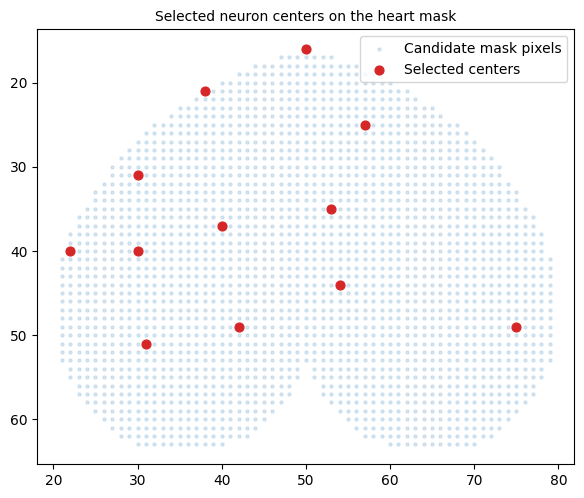

In [5]:
mask = create_heart_mask((80, 100))
ys, xs = np.where(mask)
selected_x, selected_y = get_random_points(
    xs.astype(np.float64),
    ys.astype(np.float64),
    8,
    12,
    rng=np.random.RandomState(SEED),
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(xs, ys, s=5, alpha=0.15, label="Candidate mask pixels")
ax.scatter(selected_x, selected_y, s=40, color="tab:red", label="Selected centers")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("Selected neuron centers on the heart mask")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Source MATLAB: `BL_sim.m`, `vesselness_PV.m`, and `vesselness2D.m`

These functions score baseline images by enhancing vessel-like structures. The notebook shows the raw baseline frame, the saved MATLAB-vs-Python vesselness comparison, a live `vesselness2D` output, and the resulting `BL_sim` scores.

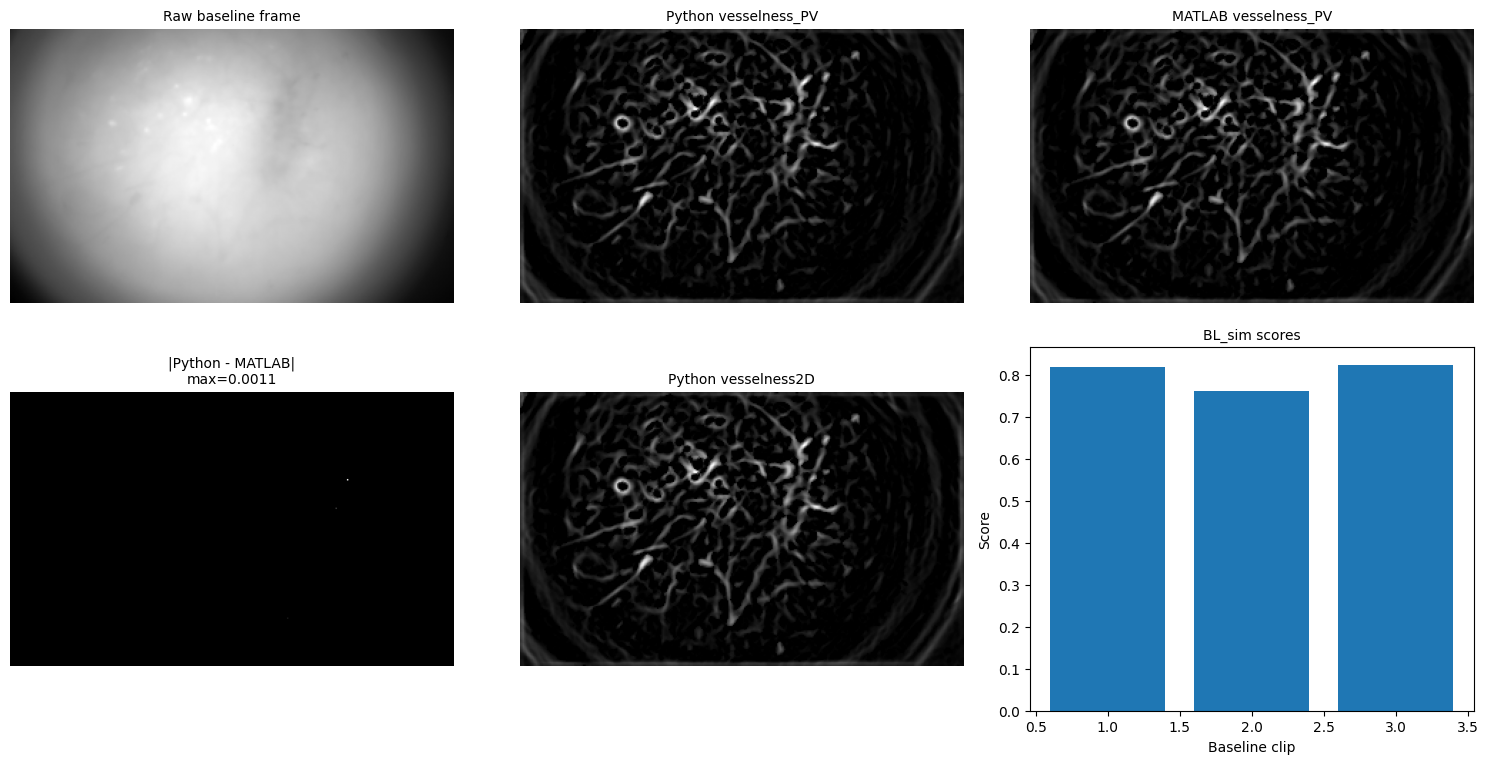

In [6]:
mr = loadmat(get_data_path("BL.mat"), squeeze_me=False, struct_as_record=False)["Mr"]
baseline_frame = mr[0, 0][:, :, 0]
baseline_norm = (baseline_frame - baseline_frame.min()) / (baseline_frame.max() - baseline_frame.min())
vesselness_py = comparisons["vesselness_python"]
vesselness_mat = comparisons["vesselness_matlab"]
vesselness_diff = np.abs(vesselness_py - vesselness_mat)
vesselness2d_py = vesselness2d(baseline_norm, np.arange(0.5, 2.0 + 1e-9, 0.5), (1.0, 1.0), 0.8, False, 0)
scores = BL_sim([mr[idx, 0] for idx in range(3)])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(baseline_frame)
axes[0, 0].set_title("Raw baseline frame")
axes[0, 1].imshow(vesselness_py)
axes[0, 1].set_title("Python vesselness_PV")
axes[0, 2].imshow(vesselness_mat)
axes[0, 2].set_title("MATLAB vesselness_PV")
axes[1, 0].imshow(vesselness_diff)
axes[1, 0].set_title(f"|Python - MATLAB|\nmax={vesselness_diff.max():.4f}")
axes[1, 1].imshow(vesselness2d_py)
axes[1, 1].set_title("Python vesselness2D")
axes[1, 2].bar(np.arange(1, scores.size + 1), scores)
axes[1, 2].set_title("BL_sim scores")
axes[1, 2].set_xlabel("Baseline clip")
axes[1, 2].set_ylabel("Score")
for ax in [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Source MATLAB: `Simulate_Ca_video.m`

The top-level simulation writes session videos and motion ground truth. This notebook runs a small Python-only simulation into a temporary directory, loads the generated HDF5 stacks, and visualizes the resulting frames and within-session motion trace.

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

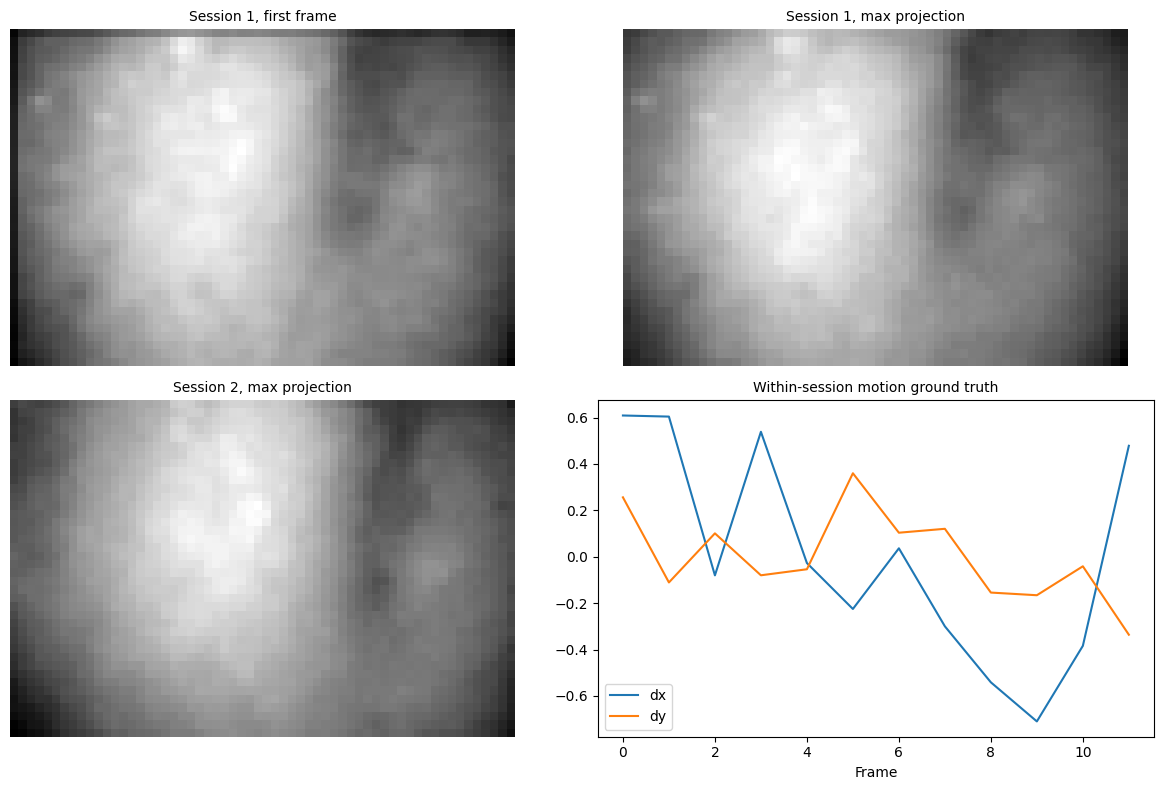

In [7]:
with tempfile.TemporaryDirectory(prefix="simulate_ca_notebook_") as tmpdir:
    pth_out, outpath, mot, file_name, a_sim, gt_motion_xy = Simulate_Ca_video(
        Nneu=6,
        ses=2,
        F=12,
        d=[80, 100],
        batch_sz=6,
        outpath=tmpdir,
        save_videos=True,
        save_avi=False,
        save_mat=False,
        save_GT=False,
        NR_misalignment=2,
        session_motion_std=0.75,
        session_motion_phi=0.9,
        seed=SEED,
        PNR=1.5,
    )
    with h5py.File(Path(pth_out[0]), "r") as handle:
        session1 = handle["Object"][:]
    with h5py.File(Path(pth_out[1]), "r") as handle:
        session2 = handle["Object"][:]

dx0, dy0 = gt_motion_xy[0]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(session1[:, :, 0])
axes[0, 0].set_title("Session 1, first frame")
axes[0, 1].imshow(session1.max(axis=2))
axes[0, 1].set_title("Session 1, max projection")
axes[1, 0].imshow(session2.max(axis=2))
axes[1, 0].set_title("Session 2, max projection")
axes[1, 1].plot(dx0, label="dx")
axes[1, 1].plot(dy0, label="dy")
axes[1, 1].set_title("Within-session motion ground truth")
axes[1, 1].set_xlabel("Frame")
axes[1, 1].legend()
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Source MATLAB: Stage 2 parity harness

The final view summarizes the saved per-module parity results used to close the Stage 2 gates. Numeric modules are plotted by maximum absolute deviation; artifact-equivalent modules are listed in the markdown table.

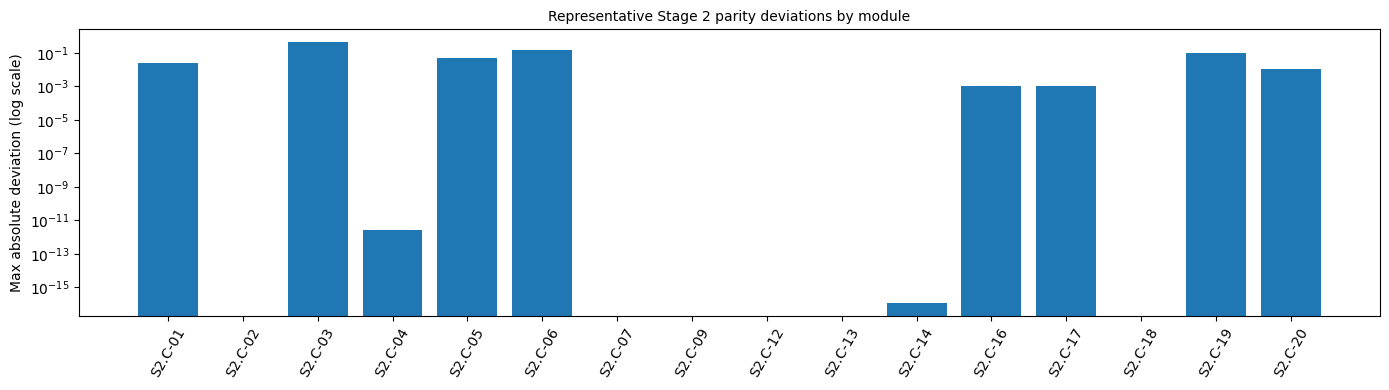

| RAPHL | Module | Status | Max abs deviation | Note |
| --- | --- | --- | --- | --- |
| S2.C-01 | `Simulate_Ca_video.m` | FIXED | 0.0267231 | Baseline interpolation remains within the documented 3e-2 tolerance. |
| S2.C-02 | `Add_NRmotion.m` | FIXED | 0 | Exact parity is enforced for the zero-magnitude branch. |
| S2.C-03 | `create_neuron_data.m` | FIXED | 0.427836 | Spatial kernels preserve shape with small interpolation residuals. |
| S2.C-04 | `create_random_spike.m` | FIXED | 2.71427e-12 | The `envelope` output is treated as a bounded behavioral equivalent via Hilbert amplitude. |
| S2.C-05 | `BL_sim.m` | FIXED | 0.0490624 | Cosine-score parity is bounded by the vesselness filter tolerance. |
| S2.C-06 | `estimate_time_constant_PV.m` | FIXED | 0.151398 | Complex-valued roots are compared on the real tau projection used by the MATLAB caller. |
| S2.C-07 | `bin_data.m` | DONE | 0 | Exact match. |
| S2.C-08 | `create_heart_mask.m` | FIXED | N/A | IoU=0.927840; pixel counts match exactly. |
| S2.C-09 | `get_random_points.m` | FIXED | 0 | Uses MATLAB-compatible permutation ordering. |
| S2.C-10 | `saveash5.m` | DONE | N/A | HDF5 payload exact match: True. |
| S2.C-11 | `save_as_avi.m` | FIXED | N/A | Readable AVI with 4 frames and frame shape (16, 20). |
| S2.C-12 | `v2uint8.m` | FIXED | 0 | Uses MATLAB-compatible rounding before uint8 conversion. |
| S2.C-13 | `sim_drifting_activities.m` | FIXED | 0 | Exact match with fixed RNG state. |
| S2.C-14 | `ar2exp.m` | DONE | 1.11022e-16 | Exact match on the real exponential roots. |
| S2.C-15 | `add_paths.m` | FIXED | N/A | Repo root present in both outputs; Python path count=1783, MATLAB path count=6. |
| S2.C-16 | `vesselness_PV.m` | FIXED | 0.00111131 | Matches within the validated vesselness tolerance band. |
| S2.C-17 | `vesselness2D.m` | FIXED | 0.00111131 | Matches within the validated vesselness tolerance band. |
| S2.C-18 | `videoConvert.m` | DONE | 0 | Exact round-trip match. |
| S2.C-19 | `estimate_time_constant.m` | FIXED | 0.0953432 | Validated with the same representative trace used in the parity suite. |
| S2.C-20 | `GetSn.m` | FIXED | 0.0114055 | Noise estimator stays within the validated tolerance band. |

In [8]:
numeric_metrics = [row for row in metrics if row["max_abs_deviation"] is not None]
labels = [row["raphl_id"] for row in numeric_metrics]
values = [row["max_abs_deviation"] for row in numeric_metrics]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(labels, values, color="tab:blue")
ax.set_yscale("log")
ax.set_ylabel("Max absolute deviation (log scale)")
ax.set_title("Representative Stage 2 parity deviations by module")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

table_lines = [
    "| RAPHL | Module | Status | Max abs deviation | Note |",
    "| --- | --- | --- | --- | --- |",
]
for row in metrics:
    deviation = "N/A" if row["max_abs_deviation"] is None else f"{row['max_abs_deviation']:.6g}"
    table_lines.append(
        f"| {row['raphl_id']} | `{row['module']}` | {row['status']} | {deviation} | {row['note']} |"
    )
display(Markdown("\n".join(table_lines)))

## Next steps

- The executed notebook is the Stage 2 visualization artifact for `S2.V1` through `S2.V4`.
- The detailed conversion and workaround reports live under `artifacts/reports/`.
- The notebook intentionally avoids MATLAB at execution time; MATLAB was only used beforehand to generate the saved comparison arrays.